In [5]:
#Clustering

import pandas as pd

df=pd.read_csv("phone_usage_india.csv")
clustering_features = [
    "Age",
    "Screen Time (hrs/day)",
    "Data Usage (GB/month)",
    "Calls Duration (mins/day)",
    "Number of Apps Installed",
    "Social Media Time (hrs/day)",
    "E-commerce Spend (INR/month)",
    "Streaming Time (hrs/day)",
    "Gaming Time (hrs/day)",
    "Monthly Recharge Cost (INR)"
]

X_cluster = df[clustering_features]

In [6]:
df.head()

,User ID,Age,Gender,Location,Phone Brand,OS,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR),Primary Use
0,U00001,53,Male,Mumbai,Vivo,Android,3.7,23.9,37.9,104,3.9,469,5.2,4.1,803,Education
1,U00002,60,Other,Delhi,Realme,iOS,9.2,28.1,13.7,169,2.8,4997,5.1,0.4,1526,Gaming
2,U00003,37,Female,Ahmedabad,Nokia,Android,4.5,12.3,66.8,96,3.0,2381,1.7,2.9,1619,Entertainment
3,U00004,32,Male,Pune,Samsung,Android,11.0,25.6,156.2,146,5.2,1185,3.2,0.3,1560,Entertainment
4,U00005,16,Male,Mumbai,Xiaomi,iOS,2.2,2.5,236.2,86,5.5,106,3.4,2.3,742,Social Media


In [7]:
df.shape

(17686, 16)

In [8]:
X_cluster.isnull().sum()

Age                             0
Screen Time (hrs/day)           0
Data Usage (GB/month)           0
Calls Duration (mins/day)       0
Number of Apps Installed        0
Social Media Time (hrs/day)     0
E-commerce Spend (INR/month)    0
Streaming Time (hrs/day)        0
Gaming Time (hrs/day)           0
Monthly Recharge Cost (INR)     0
dtype: int64

In [9]:
#Standardize the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(X_cluster)

In [10]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_cluster_scaled)
    inertia.append(kmeans.inertia_)

C:\Users\priya\AppData\Roaming\Python\Python39\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\priya\AppData\Roaming\Python\Python39\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Program Files\Python39\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Program Files\Python39\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python39\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


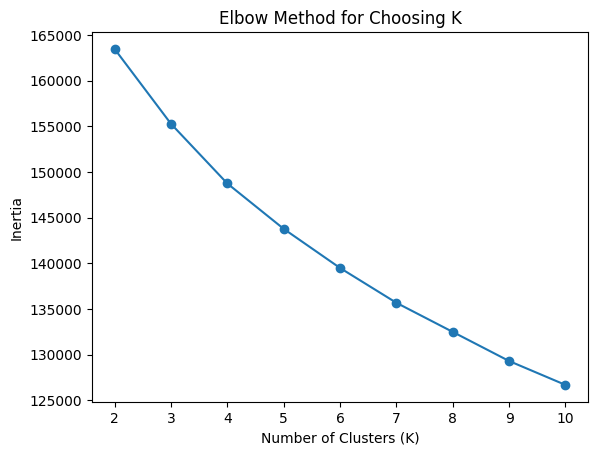

In [11]:
plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")

plt.show()

The curve drops smoothly without a distinct, sharp "elbow" point.
Observations: The rate of decrease slows down slightly around K = 4 or K =5, but the line remains fairly linear.
Challenge: When an elbow is ambiguous like this, it means the data does not have clear, naturally separated clusters.
Next Steps:  use alternative validation techniques to make a final decision. 

In [12]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_cluster_scaled)
    
    score = silhouette_score(X_cluster_scaled, cluster_labels)
    silhouette_scores.append(score)

print(silhouette_scores)

[0.07510104420670773, 0.0648711757720055, 0.06547608201814256, 0.06555262086019877, 0.06493267612603287, 0.06659914342475375, 0.06702257752956654, 0.06802983017426996, 0.06818785104952528]


Scores are all close to zero, which suggests that the users are not naturally separated into very distinct groups based on these 10 numerical features.

This is consistent with what we saw earlier:

The correlation heatmap showed weak relationships.
The group averages for Primary Use were extremely similar.
The elbow curve didn't have a strong elbow.
Now the silhouette scores are also low.

So we're seeing a consistent pattern in the dataset.

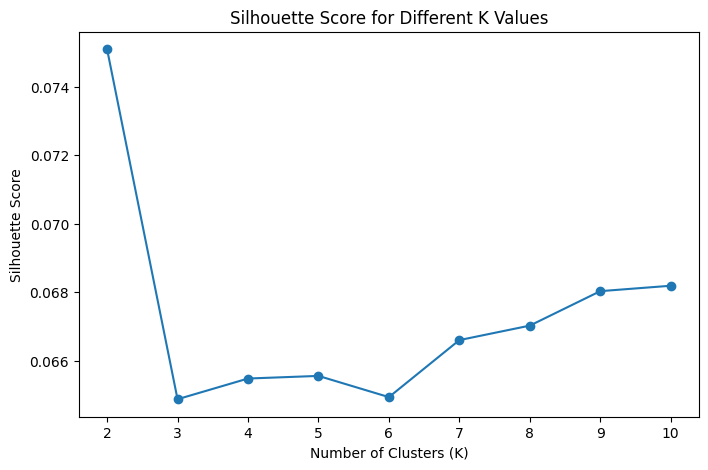

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.show()

In [14]:
#create the K-Means clusters using K = 2, since it had the highest silhouette score among the K values we tested.
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster_scaled)

In [15]:
import pandas as pd

pd.Series(cluster_labels).value_counts().sort_index()

0    8955
1    8731
Name: count, dtype: int64

So the two clusters are almost exactly equal in size.

But this doesn't tell us what makes Cluster 0 different from Cluster 1. That's what we need to investigate next.

In [16]:
#We'll create a copy of the dataframe so we don't accidentally change your original df.
df_clustered = df.copy()

df_clustered["Cluster"] = cluster_labels#adding "cluster" col

In [17]:
#Compare the cluster averages
cluster_summary = df_clustered.groupby("Cluster")[clustering_features].mean()

cluster_summary

,Age,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR)
Cluster,,,,,,,,,,
0,37.244556,6.554472,25.392150,151.720424,108.146734,3.287348,2620.142267,4.276080,2.469548,1039.058180
1,37.932654,6.538071,25.430856,151.083198,100.931623,3.216493,7594.272706,4.224499,2.512748,1046.608178


What is actually separating the two clusters?

The striking difference is E-commerce Spend:
Cluster 0: approximately ₹2,620/month
Cluster 1: approximately ₹7,594/month
That's nearly 3 times higher in Cluster 1.

There is also a smaller difference in the number of apps installed:
Cluster 0: ~108 apps
Cluster 1: ~101 apps

Most of the other phone-usage variables are extremely similar.

So, rather than saying:
"Cluster 0 consists of heavy phone users and Cluster 1 consists of light phone users"
we cannot support that conclusion from these results.

A more accurate interpretation is:
Cluster 0 and Cluster 1 have very similar overall phone-usage patterns, but they differ substantially in monthly e-commerce spending. Cluster 0 also has a somewhat higher average number of installed apps.

our silhouette score was only 0.0751 for K=2, which is quite low.

Now the cluster means help explain why: there aren't strong, broad differences between the two groups. Most usage variables are almost identical.
This gives us a consistent story across your analysis:

EDA → low correlations and similar Primary Use averages
↓
Elbow → no clear elbow
↓
Silhouette → low separation (0.0751)
↓
K-Means → two almost equally sized clusters
↓
Cluster means → clusters are very similar, with e-commerce spending being the major difference

That's actually a useful finding. clustering isn't necessarily "failing"; it is showing that the available numerical phone-usage features do not form strongly separated user groups.

In [18]:
#This code is doing PCA (Principal Component Analysis) so that the 10-dimensional clustering data can be shown on a 2D graph
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster_scaled)

print(X_pca.shape)

(17686, 2)


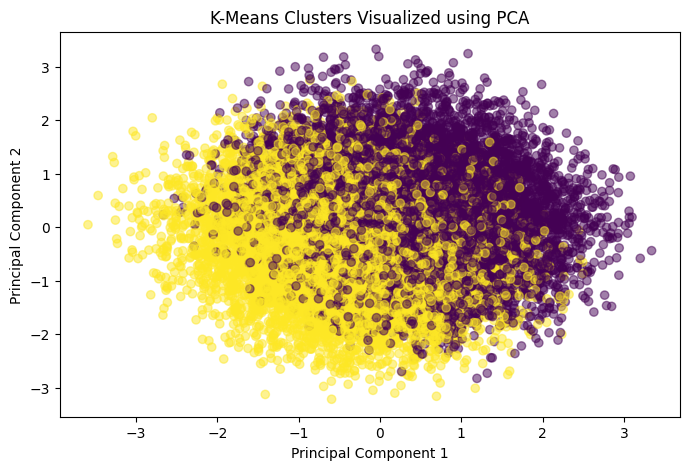

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized using PCA")

plt.show()

What the overlap means

The PCA plot shows that Cluster 0 and Cluster 1 overlap substantially.
That means users assigned to the two clusters have similar overall usage patterns, rather than forming two clearly separated groups.
This matches our earlier results:
Elbow method: no clear elbow
Silhouette score: only 0.0751
Cluster sizes: 8,955 vs 8,731 — almost equal
Cluster means: most features are very similar
PCA plot: substantial overlap

So we have consistent evidence that the dataset does not contain strongly separated user groups based on these 10 numerical features.

We shouldn't say that PCA caused the overlap. PCA is simply giving us a 2D view of the data. The low silhouette score already indicated weak separation in the original 10-dimensional space.
K-Means conclusion
K-Means clustering produced two approximately equal-sized clusters. However, the low silhouette score (0.0751) and substantial overlap in the PCA visualization indicate weak separation between the clusters. The cluster profiles were also largely similar, with monthly e-commerce spending showing the most notable difference.

In [20]:
#Hierarchical Clustering
#Hierarchical clustering can become computationally expensive with a large number of observations,
# so instead of using all 17,686 users, you're going to use 2,000 users.
sample_size = 2000

X_hierarchical = X_cluster_scaled[:sample_size]

print(X_hierarchical.shape)

(2000, 10)


In [21]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical_scores = []

for k in range(2, 7):
    
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    
    labels = model.fit_predict(X_hierarchical)
    
    score = silhouette_score(X_hierarchical, labels)
    
    hierarchical_scores.append(score)

print(hierarchical_scores)

[0.04263311872818822, 0.03152364749213627, 0.02546377067951748, 0.01968204850596473, 0.02337718266457429]


K = 2 gives the highest score: 0.0426.

But the important point is that 0.0426 is very low. This indicates that the two clusters are not strongly separated from each other.
And we can compare this with your K-Means result:
K-Means best silhouette = 0.0751 at K=2
Agglomerative best silhouette = 0.0426 at K=2
So, in our dataset:
K-Means produced somewhat better separation than Agglomerative Clustering, but both indicate weak clustering structure.
This is actually a useful finding for your project. It suggests that the 10 numerical phone-usage variables do not naturally form well-separated groups of users.

next step is to see which features differ between the hierarchical clusters, just as we did for K-Means.

In [22]:
#Create the K=2 hierarchical clusters
hierarchical_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_hierarchical)

In [23]:
#Create a dataframe for those 2,000 users
df_hierarchical = df.iloc[:sample_size].copy()

df_hierarchical["Cluster"] = hierarchical_labels

In [24]:
#Compare cluster averages
hierarchical_summary = (
    df_hierarchical
    .groupby("Cluster")[clustering_features]
    .mean()
)

hierarchical_summary

,Age,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR)
Cluster,,,,,,,,,,
0,40.782440,6.565657,24.220202,143.284460,98.734266,3.005051,4817.909091,4.68073,2.350738,881.743590
1,32.375877,6.673352,28.242777,167.654979,111.120617,3.745863,5154.447405,3.49425,2.818934,1283.725105


"Agglomerative clustering with K=2 produced two groups with some differences in demographic and usage characteristics. One group had younger users with higher data usage, call duration, app count, social-media and gaming activity, while the other had older users with greater streaming time. However, the low silhouette score (0.0426) indicates that the clusters are not strongly separated."

In [25]:
#Create PCA for the hierarchical data
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_hierarchical_pca = pca.fit_transform(X_hierarchical)

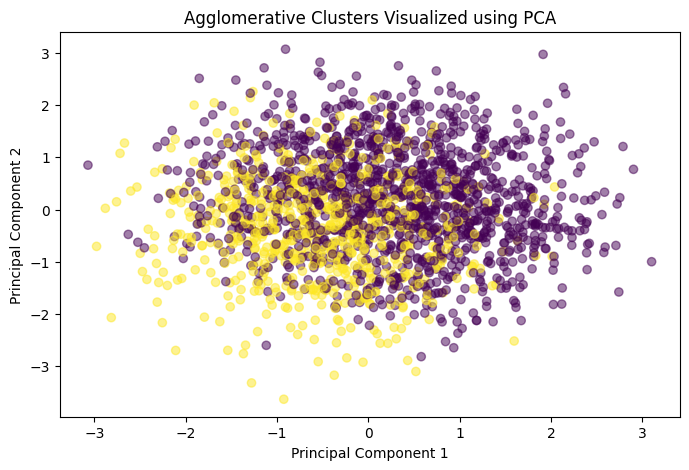

In [26]:
#Plot the hierarchical clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_hierarchical_pca[:, 0],
    X_hierarchical_pca[:, 1],
    c=hierarchical_labels,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clusters Visualized using PCA")

plt.show()

Agglomerative clustering identified two groups with some differences in usage patterns, but the substantial overlap in the PCA visualization and low silhouette score indicate weak cluster separation.

In [27]:
#DBSCAN (Density-Based Spatial Clustering of Applications with Noise.)
X_dbscan = X_hierarchical

print(X_dbscan.shape)

(2000, 10)


In [28]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=10)

neighbors.fit(X_dbscan)

distances, indices = neighbors.kneighbors(X_dbscan)

k_distances = distances[:, 9]

k_distances = sorted(k_distances)

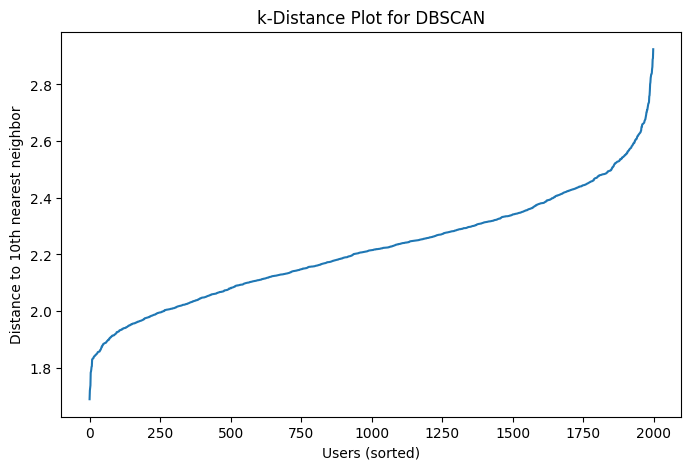

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(k_distances)

plt.xlabel("Users (sorted)")
plt.ylabel("Distance to 10th nearest neighbor")
plt.title("k-Distance Plot for DBSCAN")

plt.show()

What the plot is showing

Most of the 10th-nearest-neighbor distances increase gradually:~1.8 → 2.0 → 2.2 → 2.4 → 2.5
Then near the end, the curve starts rising more sharply:~2.5 → 2.6 → 2.7 → 2.8 → 2.9
That sharp rise is the part we're interested in.
A reasonable starting value for eps is around 2.6.
It's important that we don't say 2.6 is the "correct" eps. The k-distance plot gives us a starting point, and we then examine what DBSCAN actually produces.

In [30]:
#Run DBSCAN with eps = 2.6
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=2.6,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_dbscan)

In [31]:
import numpy as np

unique_labels = np.unique(dbscan_labels)

print("Cluster labels:", unique_labels)
print("Number of clusters:", len(unique_labels[unique_labels != -1]))
print("Number of noise points:", np.sum(dbscan_labels == -1))

Cluster labels: [0]
Number of clusters: 1
Number of noise points: 0


So DBSCAN put all 2,000 users into one single cluster.
That means eps = 2.6 is too large for this dataset with min_samples = 10.
Why?eps defines the neighborhood radius. At 2.6, the radius is large enough that the users form one connected dense region.

In [32]:
#Looking at our k-distance graph, values around 2.0–2.4 are plausible candidates. 
# Rather than arbitrarily choosing one, let's test several values and see what DBSCAN produces.
eps_values = [1.8, 2.0, 2.2, 2.4, 2.5]

for eps in eps_values:
    
    dbscan = DBSCAN(
        eps=eps,
        min_samples=10
    )
    
    labels = dbscan.fit_predict(X_dbscan)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)
    
    print(
        f"eps={eps}: "
        f"clusters={n_clusters}, "
        f"noise points={n_noise}"
    )

eps=1.8: clusters=3, noise points=1947
eps=2.0: clusters=3, noise points=887
eps=2.2: clusters=1, noise points=116
eps=2.4: clusters=1, noise points=4
eps=2.5: clusters=1, noise points=1


17,686 users, so:

At eps=1.8, about 11% of users are classified as noise.
At eps=2.0, about 5% are noise.
At eps=2.2, only about 0.7% are noise.
At eps=2.4, virtually everything is one cluster.
The interesting part

Notice what happens between eps=2.0 and eps=2.2:

eps = 2.0 → 3 clusters + 887 noise
eps = 2.2 → 1 cluster  + 116 noise

So DBSCAN is very sensitive to eps in this range.

At 2.0, it finds 3 density-based groups, but quite a lot of observations are considered noise.

At 2.2, those groups effectively merge into one large connected cluster.

That means we shouldn't simply choose 2.2 because it has fewer noise points.
investigate the eps=2.0 solution, because it is the only tested value that gives us multiple clusters without almost everything being placed into one cluster.

In [33]:
dbscan = DBSCAN(
    eps=2.0,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_dbscan)

cluster_counts = pd.Series(dbscan_labels).value_counts().sort_index()

print(cluster_counts)

-1     887
 0    1087
 1      23
 2       3
Name: count, dtype: int64


In [34]:
df_dbscan = df.iloc[:sample_size].copy()

In [35]:
cluster_analysis = df_dbscan[clustering_features].copy()

cluster_analysis["DBSCAN_Cluster"] = dbscan_labels

cluster_means = cluster_analysis.groupby("DBSCAN_Cluster").mean()

print(cluster_means)

                      Age  Screen Time (hrs/day)  Data Usage (GB/month)  \
DBSCAN_Cluster                                                            
-1              37.326945               6.833033              25.918940   
 0              38.331187               6.356486              25.639834   
 1              28.565217               9.034783              15.913043   
 2              46.333333               9.966667              27.300000   

                Calls Duration (mins/day)  Number of Apps Installed  \
DBSCAN_Cluster                                                        
-1                             151.836866                102.931229   
 0                             152.282153                104.646734   
 1                             158.773913                 42.956522   
 2                              27.766667                 87.000000   

                Social Media Time (hrs/day)  E-commerce Spend (INR/month)  \
DBSCAN_Cluster                               

DBSCAN identified three main user groups. Cluster 0 represented relatively moderate and balanced phone usage. Cluster 1 consisted of younger users with high screen-time and social-media engagement, higher e-commerce spending, and lower gaming, app count, data usage, and recharge costs. Cluster 2 represented older users with very high screen and streaming time, high e-commerce spending, and substantially lower calling activity. The strongest differences between the clusters were observed in calls duration, streaming time, e-commerce spending, age, app count, and gaming time.

In [36]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_dbscan)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.11166429 0.1077751 ]
Total explained variance: 0.2194393869860503


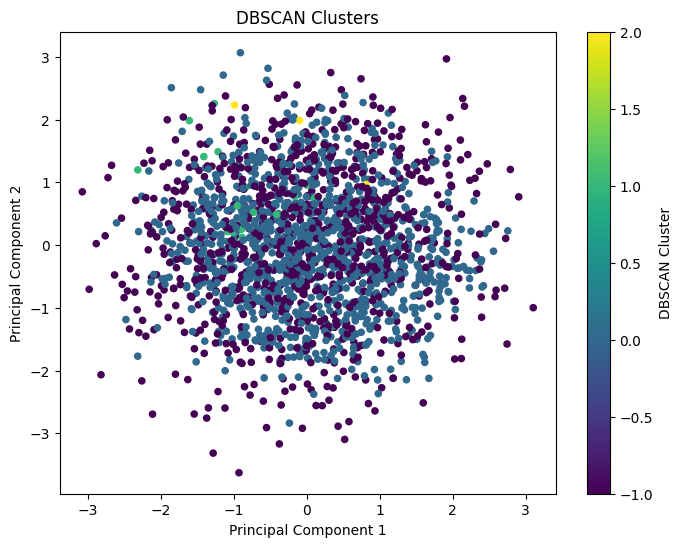

In [37]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    s=20
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clusters")
plt.colorbar(scatter, label="DBSCAN Cluster")

plt.show()

### Selection of the Final Clustering Algorithm

K-Means clustering was selected as the final algorithm for the phone usage segmentation project. K-Means, Hierarchical Clustering, and DBSCAN were explored and compared. K-Means produced two sizeable user groups containing 8,955 and 8,731 users, respectively, allowing their phone usage patterns to be compared and interpreted.

The silhouette score for K-Means at \(k=2\) was approximately 0.0751, indicating limited separation between clusters. Although the clusters are not strongly distinct, K-Means was chosen for its straightforward implementation, ease of interpretation, and suitability for presenting the overall segmentation of phone users. Hierarchical Clustering and DBSCAN were retained as alternative methods evaluated during the project.

In [38]:
import pickle

with open("best_kmeans_model.pkl", "wb") as file:
    pickle.dump(kmeans, file)

print("K-Means model saved successfully!")

K-Means model saved successfully!


In [39]:
import pickle

with open("kmeans_scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Scaler saved successfully!")

Scaler saved successfully!
